# Human immune: cell-type annotation (stage 04c)

Every cluster of the re-integrated immune lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_human_immune.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/human_immune.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "human", "immune", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_human_immune.h5ad"
TABLE = REPO / "resources/annotations/human_immune.csv"
PANEL = ['PTPRC', 'CD68', 'CSF1R', 'ITGAM', 'LYZ', 'ITGAX', 'CD3E', 'CD8A', 'CD4', 'FOXP3', 'NCAM1', 'NCR1', 'KLRD1', 'GZMB', 'TPSAB1', 'CPA3', 'MS4A2', 'KIT', 'CDH1', 'PDGFRA', 'PECAM1', 'ACTA2', 'C1QA', 'MRC1', 'CD14', 'IL7R', 'CTLA4', 'IL2RA', 'TRDC', 'MKI67']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,macrophage,55,leiden_scVI_3.0,"CD68 0.02; C1QA 0.00; MRC1 0.42; CD14 0.07 | top vs lineage: NPAS3 0.95, RHEX 0.93, MECOM 0.93"
1,EXCLUDE,240,leiden_scVI_3.0,"EXCLUDE: conservative exclusion; doublet med 11.01 (lineage q75 0.00), genes med 2718 (lineage q25 999), co-expression 0.05"
2,macrophage,182,leiden_scVI_3.0,"CD68 0.11; C1QA 0.26; MRC1 0.36; CD14 0.17 | top vs lineage: PLXDC2 0.99, SLC8A1 0.95, TBXAS1 0.93"
3,EXCLUDE,17,leiden_scVI_3.0,"EXCLUDE: conservative exclusion; doublet med 0.02 (lineage q75 0.00), genes med 1608 (lineage q25 999), co-expression 0.00"
4,macrophage,207,leiden_scVI_3.0,"CD68 0.08; C1QA 0.20; MRC1 0.78; CD14 0.28 | top vs lineage: CD163 0.90, MS4A6A 0.85, PLXDC2 0.91"
5,t_cell_cd8,138,leiden_scVI_3.0,"CD3E 0.20; CD8A 0.25; CD4 0.09 | top vs lineage: PDE3B 0.88, ANK3 0.78, SERINC5 0.62"
6,unk_cell_gzmb_high_itgax_high,431,leiden_scVI_3.0,"NCAM1 0.95; KLRD1 0.90; GZMB 0.38; ITGAX 0.82 | top vs lineage: GNLY 0.95, MCTP2 0.97, ATP8B4 0.92"
7,t_cell_gamma_delta,169,leiden_scVI_3.0,"TRDC 0.01; CD3E 0.09; KIT 0.59; IL7R 0.88 | top vs lineage: AFF3 0.92, PCDH9 0.78, SORCS1 0.74"
8,unk_cell_gzmb_low_itgax_low,608,leiden_scVI_3.0,"NCAM1 0.65; KLRD1 0.80; GZMB 0.03; ITGAX 0.03 | top vs lineage: TXK 0.92, LDB2 0.76, MCTP2 0.87"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

5066 nuclei; 28 clusters
{'t_cell_cd8': 1474, 't_cell_cd4': 856, 'macrophage': 664, 'unk_cell_gzmb_low_itgax_low': 608, 'unk_cell_gzmb_high_itgax_high': 460, 'EXCLUDE': 357, 't_cell_regulatory': 299, 'mast_cell': 179, 't_cell_gamma_delta': 169}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

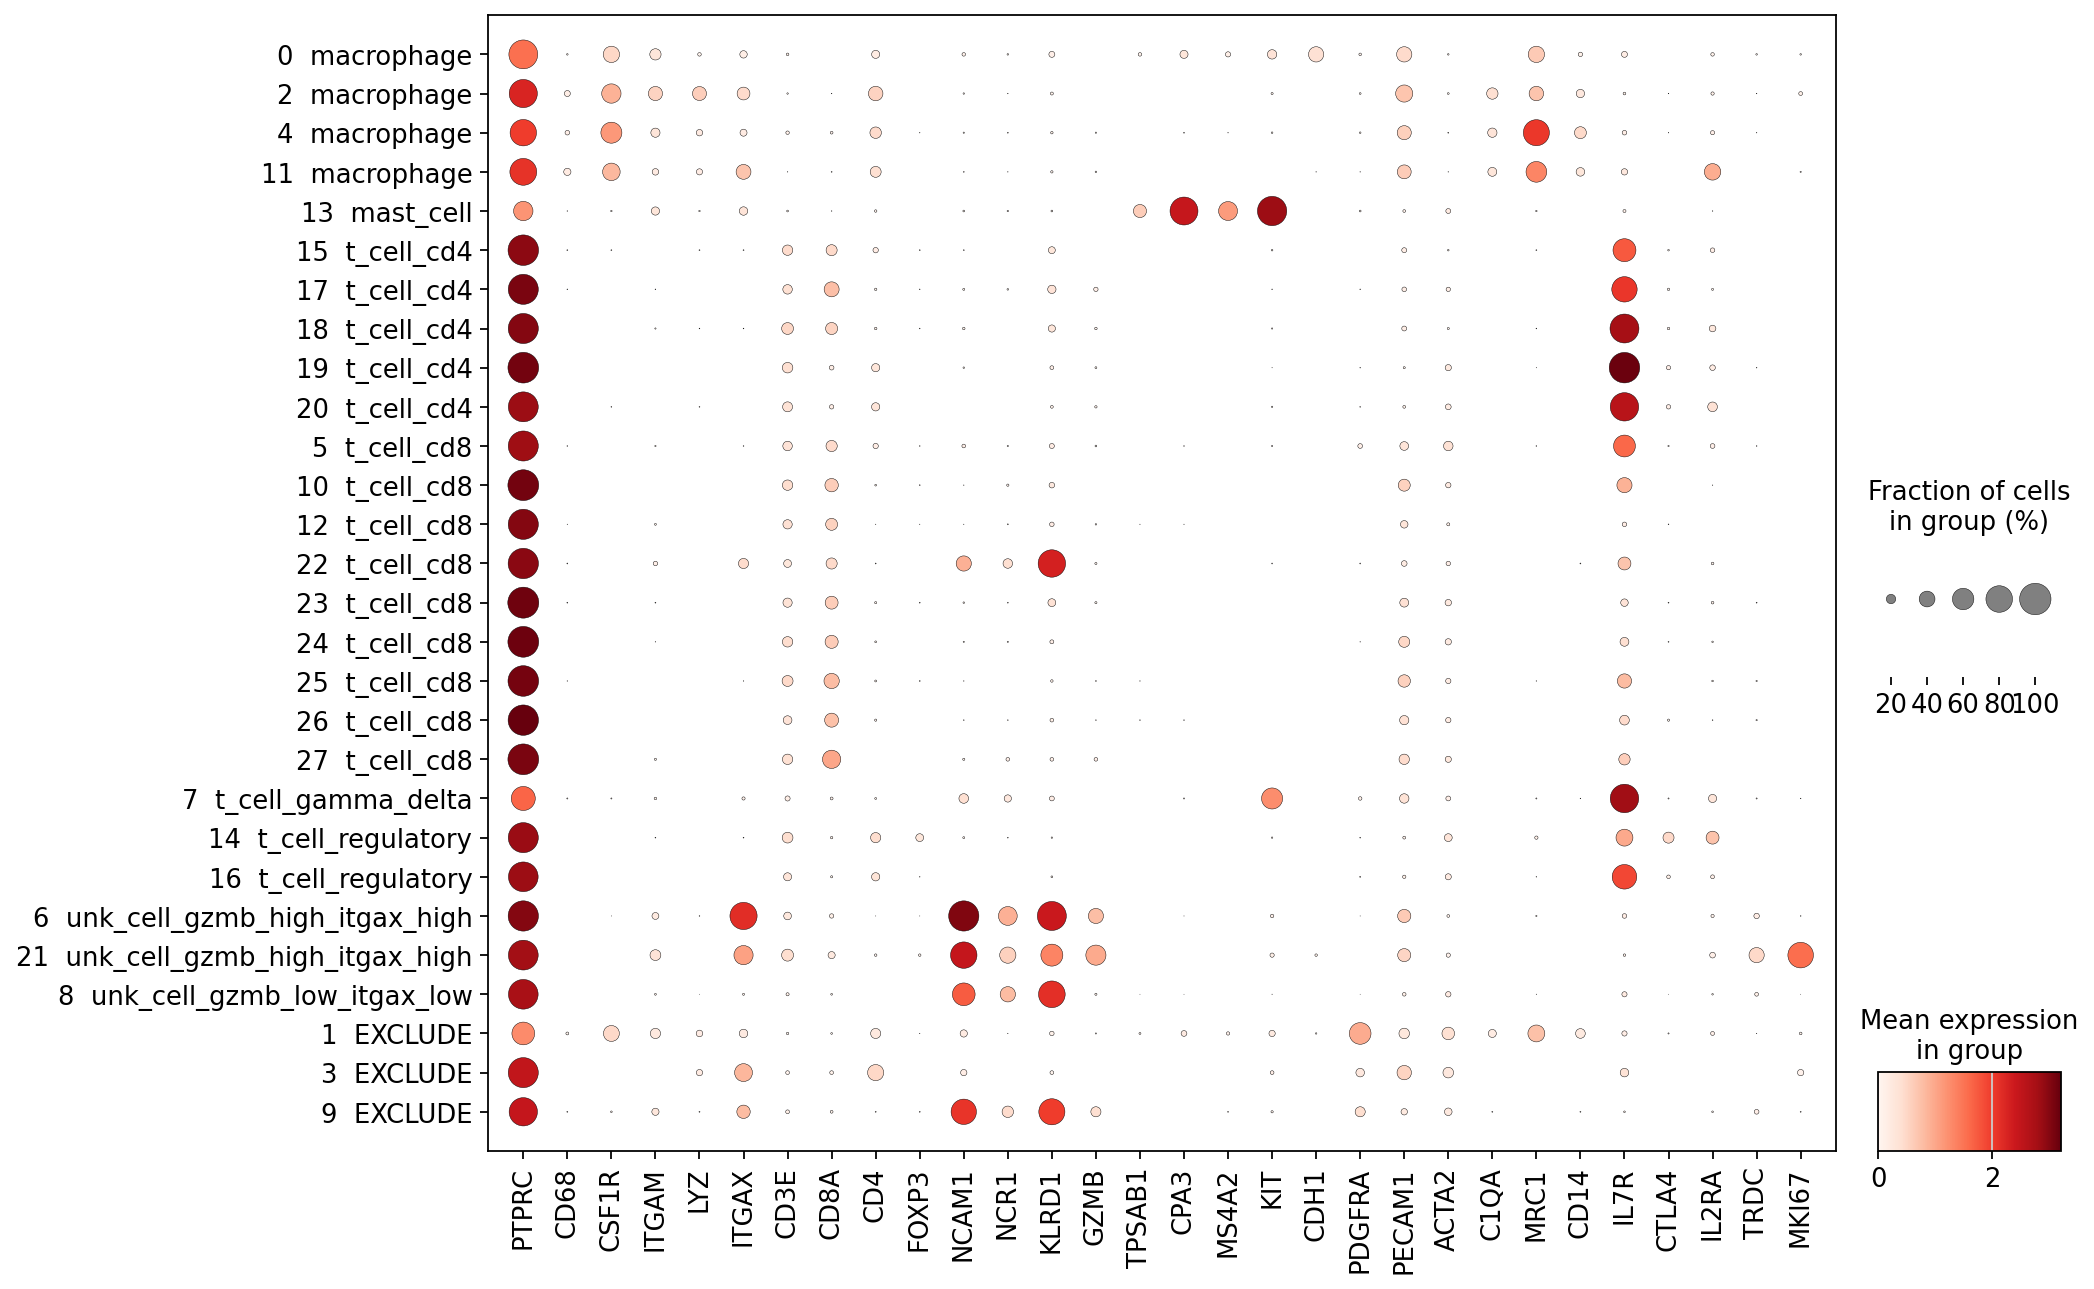

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference. A high doublet score together with markers of another lineage
(section 6) is what an EXCLUDE call rests on; a moderate score alone is not
(cycling clusters score around 1 throughout this dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
0,55,macrophage,9.47,3111.0,6190.0
2,182,macrophage,0.00,1987.5,3749.5
4,207,macrophage,0.00,1425.0,2310.0
11,220,macrophage,0.00,1594.0,2653.5
13,179,mast_cell,0.00,1229.0,1874.0
15,105,t_cell_cd4,0.00,1209.0,1804.0
17,153,t_cell_cd4,0.00,1235.0,1792.0
18,143,t_cell_cd4,0.00,1340.0,2011.0
19,330,t_cell_cd4,0.00,1401.5,2221.0


## 5. UMAP by cluster and by label

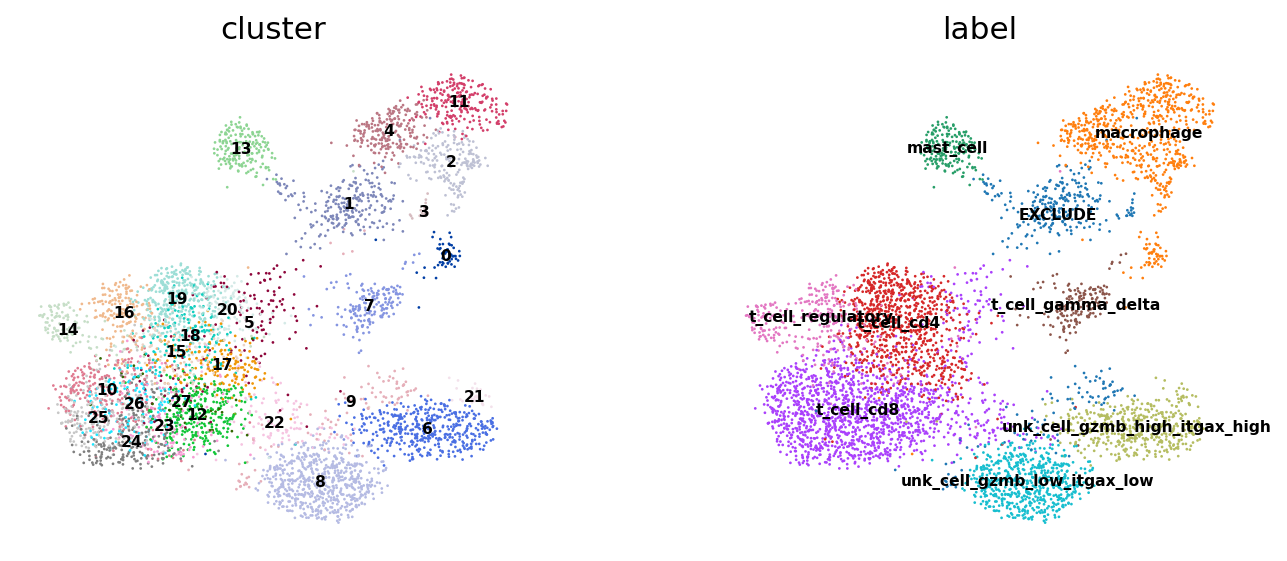

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

,PTPRC,CD68,CSF1R,ITGAM,LYZ,ITGAX,CD3E,CD8A,CD4,FOXP3,...,PECAM1,ACTA2,C1QA,MRC1,CD14,IL7R,CTLA4,IL2RA,TRDC,MKI67
1,0.65,0.04,0.40,0.23,0.12,0.18,0.03,0.02,0.22,0.00,...,0.23,0.30,0.16,0.44,0.21,0.09,0.01,0.06,0.00,0.04
3,0.94,0.00,0.00,0.00,0.12,0.47,0.06,0.06,0.41,0.00,...,0.35,0.24,0.00,0.00,0.00,0.18,0.00,0.00,0.00,0.12
9,0.87,0.01,0.02,0.14,0.01,0.32,0.06,0.04,0.01,0.01,...,0.12,0.15,0.01,0.00,0.01,0.02,0.00,0.02,0.08,0.01
lineage,0.89,0.02,0.09,0.07,0.03,0.14,0.14,0.14,0.09,0.01,...,0.18,0.09,0.03,0.10,0.04,0.32,0.02,0.07,0.02,0.01
